# Day 19/100 — ReturnReason Classifier · FULL MASTER v3

**Goal:** classify Indonesian product-return reasons across `defect`, `wrong_item`, `missing_item`, `late_delivery`, `size`. Optional `other` is a **manual review outcome**, NOT a sixth learned class.

**Integrity contract:** Previous v2 achieved 74.95% on 240 held-out synthetic-template examples, but incorrectly predicted “Sepatu ini kekecilan” as `defect`. We preserve the experimental source hierarchy rather than inflating synthetic training sizes:

- Bitext: English support intent proxy (NOT customer return reason ground truth).
- Return Abuse: categorical `return_reason` only; taxonomy audit, NEVER text-label training by copying that column.
- SEA: multilingual synthetic support; filtered Indonesian subset provides a small external diagnostic, not proof of production readiness.
- Indonesian hand-written templates: artificial training development only.
- **Optional independent human-annotated file** (`real_return_annotations.csv`) supplies truthful Indonesian evaluation. Do not train/tune on its test labels.

Selection only by synthetic validation. Test and external datasets are diagnostic. A high score on synthetic data cannot justify real-world claims. Notebook is fully runnable without optional gold/IndoBERT; any optional missing component is explicitly reported. Configure Kaggle Internet ON for IndoBERT model download; GPU preferred.

Outputs: `/kaggle/working/returnreason_master_v3/{models,reports,assets/plots,exports}` and `/kaggle/working/ReturnReason_Day19_FULL_MASTER_v3_RELEASE.zip`. No raw copyrighted datasets included in release.

In [1]:
from pathlib import Path
import os, sys, json, re, hashlib, zipfile, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
SEED=42
np.random.seed(SEED)
ROOT=Path('/kaggle/input/datasets/wafabila/returnreason-classifier-multi-source-dataset')
assert ROOT.is_dir(), f'Missing Kaggle Add Input: {ROOT}'
OUT=Path('/kaggle/working/returnreason_master_v3')
for folder in ['models','reports','assets/plots','exports']:(OUT/folder).mkdir(parents=True,exist_ok=True)
RUN_INDOBERT=True  # GPU + internet recommended; failures gracefully recorded
MODEL_ID='indobenchmark/indobert-base-p1'
LABELS=['defect','late_delivery','missing_item','size','wrong_item']
print('Python',sys.version.split()[0],'input',ROOT,'output',OUT)


Python 3.13.15 input /kaggle/input/datasets/wafabila/returnreason-classifier-multi-source-dataset output /kaggle/working/returnreason_master_v3


## 1. Source audit — require exact expected columns, no guessing

In [2]:
files=sorted(p for p in ROOT.rglob('*') if p.is_file() and p.suffix.lower() in {'.csv','.parquet'})
assert files, 'Dataset root has no CSV/Parquet files'
def get_source(required, preferred):
    matches=[]
    for p in files:
        try:
            d=pd.read_csv(p,encoding='utf-8-sig',low_memory=False) if p.suffix=='.csv' else pd.read_parquet(p)
            if set(required).issubset(d.columns):
                matches.append((preferred in str(p).lower(),len(d),p,d))
        except Exception as exc: print('SKIP',p.name,str(exc)[:100])
    assert matches, f'Cannot find source columns {required}'
    matches.sort(key=lambda x:(x[0],x[1]),reverse=True)
    _,_,p,d=matches[0]
    print(p,'rows',len(d),'cols',list(d.columns))
    return d,p
bitext,b_path=get_source({'instruction','intent'},'bitext-retail')
abuse,a_path=get_source({'return_reason'},'ecommerce-returns')
sea,s_path=get_source({'customer_message','language','intent'},'return-reasons-id')
source_manifest={'bitext':{'path':str(b_path),'rows':len(bitext)},'return_abuse':{'path':str(a_path),'rows':len(abuse)},'sea':{'path':str(s_path),'rows':len(sea)}}
(OUT/'reports/source_manifest.json').write_text(json.dumps(source_manifest,indent=2),encoding='utf-8')
print('return abuse taxonomy ONLY');display(abuse.return_reason.value_counts().head(20))
print('SEA language distribution');display(sea.language.value_counts())


/kaggle/input/datasets/wafabila/returnreason-classifier-multi-source-dataset/bitext-retail/bitext-retail-ecommerce-llm-chatbot-training-dataset.csv rows 44884 cols ['instruction', 'intent', 'category', 'tags', 'response']
/kaggle/input/datasets/wafabila/returnreason-classifier-multi-source-dataset/ecommerce-returns/ecommerce_return_abuse_dataset.csv rows 60000 cols ['order_id', 'customer_id', 'age', 'account_age_days', 'customer_segment', 'country', 'platform', 'device_type', 'payment_method', 'product_category', 'avg_order_value_usd', 'refund_amount_requested_usd', 'is_high_value_item', 'discount_used', 'order_date', 'return_date', 'days_to_return', 'return_reason', 'total_orders_lifetime', 'total_returns_lifetime', 'return_rate_pct', 'item_returned_opened', 'return_packaging_intact', 'photo_evidence_provided', 'tracking_number_valid', 'shipping_carrier', 'address_change_before_delivery', 'refund_to_different_account', 'multiple_accounts_flag', 'customer_support_contacts', 'previous_d

return_reason
Not As Described      8320
Defective/Broken      7095
Changed Mind          6850
Wrong Item Sent       6138
Too Large             5870
Too Small             5817
Quality Issue         4354
Found Better Price    3931
Item Not Received     3845
Arrived Late          3294
Gift Duplicate        2791
Accidental Order      1695
Name: count, dtype: int64

SEA language distribution


language
en    270
ms    247
zh    246
id    237
Name: count, dtype: int64

## 2. Honest synthetic development corpus: 50 independently held-out **template families**

In [3]:
TEMPLATES={
'defect':[
 'Barang {item} saya rusak waktu dibuka {ending}', 'Saya mau retur karena {item} yang dikirim sudah pecah {ending}',
 '{item} tidak berfungsi sama sekali padahal baru diterima {ending}', 'Kondisi {item} cacat dan ada bagian yang retak {ending}',
 'Produk {item} bermasalah: tombolnya tidak bisa dipakai {ending}', 'Saya menemukan kerusakan pada {item} setelah unboxing {ending}',
 'Barang {item} datang dalam keadaan penyok dan lecet parah {ending}', 'Baru sekali digunakan, {item} langsung mati {ending}',
 'Ada komponen {item} yang patah, jadi tidak dapat dipakai {ending}', 'Saya minta pengembalian karena {item} mengalami kerusakan {ending}'],
'wrong_item':[
 'Saya pesan {item} tapi yang diterima model lain {ending}', 'Warna {item} yang datang salah dari pesanan {ending}',
 'Penjual mengirim barang yang berbeda dengan {item} pilihan saya {ending}', 'Isi paket tidak sesuai foto produk {item} yang saya pilih {ending}',
 '{item} yang terkirim bukan varian yang saya checkout {ending}', 'Saya pilih {item}, ternyata kirimannya tipe lain {ending}',
 'Produk dalam dus tidak sama dengan {item} yang ada di invoice {ending}', 'Salah kirim, bukan {item} ini yang saya beli {ending}',
 'Pesanan {item} tertukar dengan produk lain {ending}', 'Barang yang diterima berbeda SKU dari {item} yang dibeli {ending}'],
'missing_item':[
 'Paket datang tapi {item} tidak ada di dalam kotak {ending}', 'Saya beli {item} tetapi item itu tidak ikut dikirim {ending}',
 'Ada barang yang kurang, yaitu {item} {ending}', 'Pesanan diterima tapi {item} hilang dari isi paket {ending}',
 'Jumlah barang tidak lengkap, {item} belum ada {ending}', '{item} tercantum dalam pesanan namun tidak ditemukan di paket {ending}',
 'Kotak sudah sampai, tetapi {item} ternyata tidak disertakan {ending}', 'Satu barang belum masuk pengiriman yaitu {item} {ending}',
 'Isi kiriman kurang satu, saya tidak menemukan {item} {ending}', 'Paket diterima lengkap kemasannya tetapi produk {item} tidak ada {ending}'],
'late_delivery':[
 'Pesanan {item} datang jauh melewati estimasi pengiriman {ending}', 'Pengiriman {item} terlambat beberapa hari {ending}',
 'Barang {item} baru tiba setelah tanggal yang dijanjikan {ending}', 'Saya mau komplain karena paket {item} sampai telat {ending}',
 '{item} tiba sesudah tenggat waktu pengiriman {ending}', 'Kurir membawa {item} lebih lama dari jadwal {ending}',
 'Paket {item} akhirnya datang, tetapi sudah lewat estimasi {ending}', 'Sudah menunggu lama dan {item} terlambat diterima {ending}',
 'Pengantaran {item} lewat dari hari yang tertera pada aplikasi {ending}', 'Kiriman {item} molor sampai beberapa hari setelah jadwal {ending}'],
'size':[
 'Ukuran {item} kekecilan ketika saya coba {ending}', 'Saya pesan {item} tapi ukurannya terlalu besar {ending}',
 '{item} tidak muat di badan saya {ending}', 'Size {item} berbeda dengan ukuran yang saya butuhkan {ending}',
 '{item} kebesaran dan tidak pas dipakai {ending}', 'Saya ingin tukar karena ukuran {item} terlalu sempit {ending}',
 'Panjang {item} tidak cocok dengan tubuh saya {ending}', 'Saya salah pilih size untuk {item}, ingin retur {ending}',
 '{item} terlalu longgar di bagian pinggang {ending}', 'Ukuran {item} tidak pas di kaki saya {ending}']}
ITEMS={
 'defect':['lampu meja','headset','blender','jam digital','speaker bluetooth','pengisi daya','botol kaca','kamera kecil'],
 'wrong_item':['tas sekolah','botol minum','mouse','jaket','sepatu olahraga','buku','lampu','powerbank'],
 'missing_item':['kabel charger','kaos','gelas','spatula','headset','sabun','pensil','gantungan kunci'],
 'late_delivery':['sepatu','tas','baju','mainan','buku','headset','lampu','peralatan masak'],
 'size':['sepatu','jaket','kaos','celana','sandal','kemeja','rok','hoodie']}
ENDINGS=['','tolong dibantu','mohon diproses','saya ingin ajukan retur','ini mengecewakan','bagaimana solusinya','tolong cek','saya butuh pengembalian','bisa bantu?','saya tidak bisa memakainya']
assert all(len(v)==10 for v in TEMPLATES.values())
rows=[]
for label, families in TEMPLATES.items():
    for i,fmt in enumerate(families):
        family=f'{label}_{i:02d}'
        # Deterministic 24 variants per family, without memorized repeated exact sentences
        rng=np.random.default_rng(SEED+i+sum(map(ord,label)))
        combos=[(item,end) for item in ITEMS[label] for end in ENDINGS]
        rng.shuffle(combos)
        for item,end in combos[:24]:
            txt=' '.join(fmt.format(item=item,ending=end).split()).strip()
            rows.append({'text':txt,'label':label,'template_family':family,'source':'manual_template_generated','language':'id'})
synthetic=pd.DataFrame(rows).drop_duplicates('text').reset_index(drop=True)
print('Synthetic data:',synthetic.shape,'class counts:',synthetic.label.value_counts().to_dict(), 'family counts:', synthetic.groupby('label').template_family.nunique().to_dict())
display(synthetic.groupby('label').head(2))
synthetic.to_csv(OUT/'exports/synthetic_indonesian_development.csv',index=False)
(OUT/'reports/synthetic_generation_contract.json').write_text(json.dumps({'provenance':'Manually authored 50 semantic templates, programmatically varied items/endings; not real customer annotations','seed':SEED,'classes':list(TEMPLATES),'families_per_class':10,'n_rows':len(synthetic),'limitations':['Lexical overlap across template families','Synthetic holdout is not real-world evaluation','Template-derived labels are not independently annotated']},ensure_ascii=False,indent=2),encoding='utf-8')

Synthetic data: (1200, 5) class counts: {'defect': 240, 'wrong_item': 240, 'missing_item': 240, 'late_delivery': 240, 'size': 240} family counts: {'defect': 10, 'late_delivery': 10, 'missing_item': 10, 'size': 10, 'wrong_item': 10}


,text,label,template_family,source,language
0,Barang kamera kecil saya rusak waktu dibuka sa...,defect,defect_00,manual_template_generated,id
1,Barang lampu meja saya rusak waktu dibuka baga...,defect,defect_00,manual_template_generated,id
240,Saya pesan botol minum tapi yang diterima mode...,wrong_item,wrong_item_00,manual_template_generated,id
241,Saya pesan jaket tapi yang diterima model lain...,wrong_item,wrong_item_00,manual_template_generated,id
480,Paket datang tapi spatula tidak ada di dalam k...,missing_item,missing_item_00,manual_template_generated,id
481,Paket datang tapi gantungan kunci tidak ada di...,missing_item,missing_item_00,manual_template_generated,id
720,Pesanan sepatu datang jauh melewati estimasi p...,late_delivery,late_delivery_00,manual_template_generated,id
721,Pesanan mainan datang jauh melewati estimasi p...,late_delivery,late_delivery_00,manual_template_generated,id
960,Ukuran kemeja kekecilan ketika saya coba ini m...,size,size_00,manual_template_generated,id
961,Ukuran rok kekecilan ketika saya coba bagaiman...,size,size_00,manual_template_generated,id


483

## 3. Split by template family: train 70% / validation 10% / test 20%

In [4]:
rng=np.random.default_rng(SEED)
assign={}
for label in sorted(synthetic.label.unique()):
    groups=sorted(synthetic.loc[synthetic.label.eq(label),'template_family'].unique())
    rng.shuffle(groups)
    for split,gs in [('train',groups[:7]),('validation',groups[7:8]),('test',groups[8:])]:
        assign.update({g:split for g in gs})
synthetic['split']=synthetic.template_family.map(assign)
train_id=synthetic[synthetic.split.eq('train')].copy()
val_id=synthetic[synthetic.split.eq('validation')].copy()
test_id=synthetic[synthetic.split.eq('test')].copy()
for a,b in [(train_id,val_id),(train_id,test_id),(val_id,test_id)]:
    assert not (set(a.template_family)&set(b.template_family))
    assert not (set(a.text)&set(b.text))
print(synthetic.groupby(['split','label']).size().unstack(fill_value=0))
synthetic.groupby(['split','label']).size().unstack(fill_value=0).to_csv(OUT/'reports/split_class_counts.csv')
# Simpan data pengembangan sintetis; release ZIP tidak menyertakan data sintetik seluruhnya.

label       defect  late_delivery  missing_item  size  wrong_item
split                                                            
test            48             48            48    48          48
train          168            168           168   168         168
validation      24             24            24    24          24


## 4. External Indonesian diagnostic + optional real human-labeled test

In [5]:
SEA_MAP={'product_defect':'defect','wrong_item_received':'wrong_item','shipping_delay':'late_delivery','missing_item':'missing_item'}
sea_id=sea.loc[sea.language.astype(str).str.strip().str.lower().eq('id'),['customer_message','intent']].copy()
sea_id['label']=sea_id.intent.astype(str).str.strip().str.lower().map(SEA_MAP)
sea_id=sea_id.dropna(subset=['customer_message','label']).rename(columns={'customer_message':'text'})
sea_id['text']=sea_id.text.astype(str).str.strip()
sea_id=sea_id[sea_id.text.str.len().ge(8)].copy()
sea_id['source']='SEA_ID_synthetic_external'
print('SEA filtered Indonesian',len(sea_id),sea_id.label.value_counts().to_dict())
# Optional upload real_return_annotations.csv under any attached Kaggle input dir:
# columns: text,label,review_status; review_status must be verified, source must be legally usable.
# We never auto-promote synthetic feedback to verified test.
gold_candidates=[p for p in Path('/kaggle/input').rglob('real_return_annotations.csv') if p.is_file()]
gold=pd.DataFrame(columns=['text','label'])
if gold_candidates:
    gd=pd.read_csv(gold_candidates[0],encoding='utf-8-sig')
    required={'text','label','review_status'}
    assert required.issubset(gd.columns),f'Gold data requires {required}'
    gold=gd.loc[gd.review_status.astype(str).str.lower().eq('verified'),['text','label']].copy()
    gold['text']=gold.text.fillna('').astype(str).str.strip()
    gold['label']=gold.label.astype(str).str.strip()
    gold=gold[gold.label.isin(LABELS)&gold.text.str.len().ge(8)].drop_duplicates('text')
    contaminated=set(gold.text.str.lower())&set(synthetic.text.str.lower())
    assert not contaminated, 'Gold corpus overlaps the authored synthetic set: remove overlapping samples before testing'
    print('VERIFIED GOLD independently annotated rows:',len(gold),'classes:',gold.label.value_counts().to_dict())
else: print('NO human-verified gold found. Real customer performance remains UNKNOWN.')


SEA filtered Indonesian 34 {'late_delivery': 15, 'defect': 10, 'wrong_item': 9}
NO human-verified gold found. Real customer performance remains UNKNOWN.


## 5. English intent-proxy features: optional training supplement, no label shortcut

In [6]:
BITEXT_MAP={'damaged_delivery':'defect','wrong_item':'wrong_item','missing_item':'missing_item','delivery_time':'late_delivery'}
b_en=bitext[['instruction','intent']].copy().rename(columns={'instruction':'text'})
b_en['label']=b_en.intent.astype(str).str.strip().str.lower().map(BITEXT_MAP)
b_en=b_en[b_en.label.notna() & b_en.text.notna()].drop_duplicates(subset=['text']).copy()
b_en['source']='bitext_en_intent_proxy';b_en['language']='en'
print('Optional English proxy rows',len(b_en),b_en.label.value_counts().to_dict())
assert b_en.label.nunique()>=3

Optional English proxy rows 3629 {'wrong_item': 996, 'defect': 992, 'late_delivery': 920, 'missing_item': 721}


## 6. Compare lexical baselines; select by synthetic validation, not external test

In [7]:
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

train_pool=pd.concat([train_id[['text','label']], b_en[['text','label']]],ignore_index=True)
specs={
 'majority':('id',Pipeline([('tfidf',TfidfVectorizer()),('clf',DummyClassifier(strategy='most_frequent'))])),
 'id_word_svm':('id',Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('clf',LinearSVC(class_weight='balanced',random_state=SEED))])),
 'id_char_svm':('id',Pipeline([('tfidf',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=160000,sublinear_tf=True)),('clf',LinearSVC(class_weight='balanced',random_state=SEED))])),
 'id_char_logreg':('id',Pipeline([('tfidf',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=160000,sublinear_tf=True)),('clf',LogisticRegression(class_weight='balanced',max_iter=1200,random_state=SEED))])),
 'bilingual_char_svm':('mix',Pipeline([('tfidf',TfidfVectorizer(analyzer='char',ngram_range=(2,5),min_df=2,max_features=180000,sublinear_tf=True)),('clf',LinearSVC(class_weight='balanced',random_state=SEED))]))
}
rows=[];trained={}
for name,(kind,pipe) in specs.items():
    d=train_id if kind=='id' else train_pool
    start=time.perf_counter();pipe.fit(d.text.astype(str),d.label)
    pred=pipe.predict(val_id.text.astype(str))
    rows.append({'model':name,'train_rows':len(d),'train_source':kind,'validation_macro_f1':float(f1_score(val_id.label,pred,average='macro',labels=LABELS,zero_division=0)),'validation_accuracy':float(accuracy_score(val_id.label,pred)),'seconds':round(time.perf_counter()-start,2)})
    trained[name]=pipe
rank=pd.DataFrame(rows).sort_values(['validation_macro_f1','validation_accuracy','model'],ascending=[False,False,True])
display(rank)
rank.to_csv(OUT/'reports/model_comparison.csv',index=False)
champion_name=str(rank.iloc[0].model)
champion=trained[champion_name]
print('Lexical champion (validation only):',champion_name)


,model,train_rows,train_source,validation_macro_f1,validation_accuracy,seconds
2,id_char_svm,840,id,0.957876,0.958333,0.20
3,id_char_logreg,840,id,0.956979,0.958333,1.81
1,id_word_svm,840,id,0.903252,0.908333,0.04
4,bilingual_char_svm,4469,mix,0.834620,0.858333,0.82
0,majority,840,id,0.066667,0.200000,0.03


Lexical champion (validation only): id_char_svm


## 7. OPTIONAL pretrained IndoBERT comparison

This trains a classifier head and fine-tunes the pretrained encoder, not from scratch. It is **not** guaranteed to beat TF-IDF with small synthetic training. Uses PyTorch directly (no `Trainer`/`TrainingArguments` API issues). If no GPU/model access, records a skip and retains a runnable lexical release. IndoBERT is not tuned against SEA or real gold.

In [8]:
bert_status={'requested':RUN_INDOBERT,'completed':False,'reason':None}
bert_model=None; bert_tok=None; bert_metrics=None
if RUN_INDOBERT:
    try:
        import torch
        from torch.utils.data import Dataset,DataLoader
        from transformers import AutoTokenizer,AutoModelForSequenceClassification, get_linear_schedule_with_warmup
        if not torch.cuda.is_available():
            raise RuntimeError('No CUDA GPU; skip expensive IndoBERT CPU training. Enable Kaggle GPU then rerun.')
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
        device=torch.device('cuda')
        bert_tok=AutoTokenizer.from_pretrained(MODEL_ID)
        label2id={v:i for i,v in enumerate(LABELS)}
        bert_model=AutoModelForSequenceClassification.from_pretrained(MODEL_ID,num_labels=len(LABELS),id2label={i:x for x,i in label2id.items()},label2id=label2id)
        bert_model.to(device)
        class TxtDS(Dataset):
            def __init__(self,df):
                self.enc=bert_tok(df.text.astype(str).tolist(),padding=False,truncation=True,max_length=96)
                self.labels=[label2id[x] for x in df.label]
            def __len__(self):return len(self.labels)
            def __getitem__(self,i):return {**{k:torch.tensor(v[i],dtype=torch.long) for k,v in self.enc.items()},'labels':torch.tensor(self.labels[i],dtype=torch.long)}
        from transformers import DataCollatorWithPadding
        collator=DataCollatorWithPadding(tokenizer=bert_tok)
        tr_loader=DataLoader(TxtDS(train_id),batch_size=16,shuffle=True,collate_fn=collator)
        va_loader=DataLoader(TxtDS(val_id),batch_size=32,shuffle=False,collate_fn=collator)
        optim=torch.optim.AdamW(bert_model.parameters(),lr=2e-5,weight_decay=0.01)
        epochs=3;total_steps=len(tr_loader)*epochs
        sched=get_linear_schedule_with_warmup(optim,num_warmup_steps=max(1,total_steps//10),num_training_steps=total_steps)
        best=-1;best_state=None;hist=[]
        for ep in range(epochs):
            bert_model.train();losses=[]
            for batch in tr_loader:
                batch={k:v.to(device) for k,v in batch.items()}
                optim.zero_grad(set_to_none=True)
                out=bert_model(**batch);out.loss.backward()
                torch.nn.utils.clip_grad_norm_(bert_model.parameters(),1.0)
                optim.step();sched.step();losses.append(float(out.loss.detach().cpu()))
            bert_model.eval();ps=[];ys=[]
            with torch.no_grad():
                for batch in va_loader:
                    ys.extend(batch['labels'].tolist());batch={k:v.to(device) for k,v in batch.items()}
                    ps.extend(bert_model(**batch).logits.argmax(-1).cpu().tolist())
            score=float(f1_score(ys,ps,average='macro',labels=list(range(len(LABELS))),zero_division=0))
            hist.append({'epoch':ep+1,'train_loss':float(np.mean(losses)),'val_macro_f1':score})
            print('IndoBERT epoch',ep+1,'loss',round(np.mean(losses),4),'val Macro-F1',round(score,4))
            if score>best:
                best=score;best_state={k:v.detach().cpu().clone() for k,v in bert_model.state_dict().items()}
        bert_model.load_state_dict(best_state);bert_model.to(device);bert_model.eval()
        bert_status.update({'completed':True,'validation_macro_f1':best,'epochs':epochs})
        pd.DataFrame(hist).to_csv(OUT/'reports/indobert_training_history.csv',index=False)
        if best>float(rank.iloc[0].validation_macro_f1):
            (OUT/'models/indobert').mkdir(parents=True,exist_ok=True)
            bert_model.save_pretrained(OUT/'models/indobert',safe_serialization=True)
            bert_tok.save_pretrained(OUT/'models/indobert')
            bert_status['selected_for_release']=True
        else: bert_status['selected_for_release']=False
    except Exception as exc:
        bert_status['reason']=f'{type(exc).__name__}: {exc}'
        bert_model=None;bert_tok=None
        print('IndoBERT skipped/failed:',bert_status['reason'])
(OUT/'reports/indobert_status.json').write_text(json.dumps(bert_status,indent=2),encoding='utf-8')


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


IndoBERT epoch 1 loss 0.7006 val Macro-F1 0.9833
IndoBERT epoch 2 loss 0.0086 val Macro-F1 1.0
IndoBERT epoch 3 loss 0.0048 val Macro-F1 1.0


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

139

## 8. Frozen selection, one-time heldout evaluation and gold external assessment

SELECTED indobenchmark/indobert-base-p1 (validation-only winner)


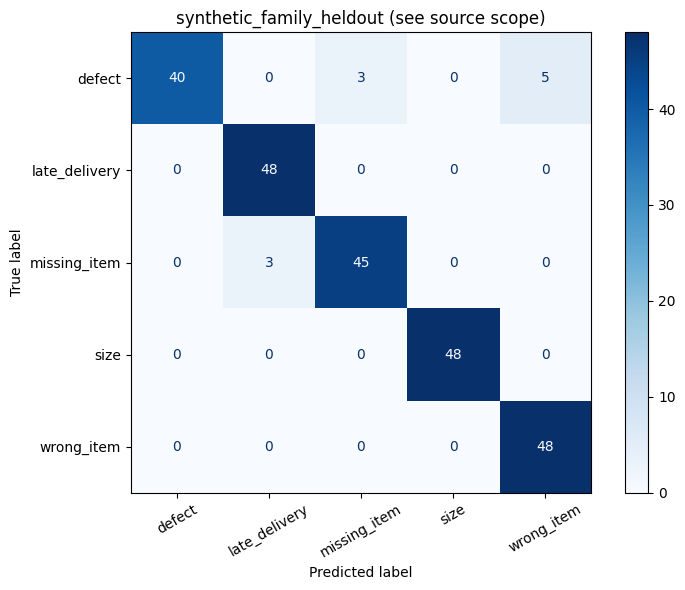

synthetic_family_heldout N 240 accuracy 0.9542 macro F1 all 5 0.9534


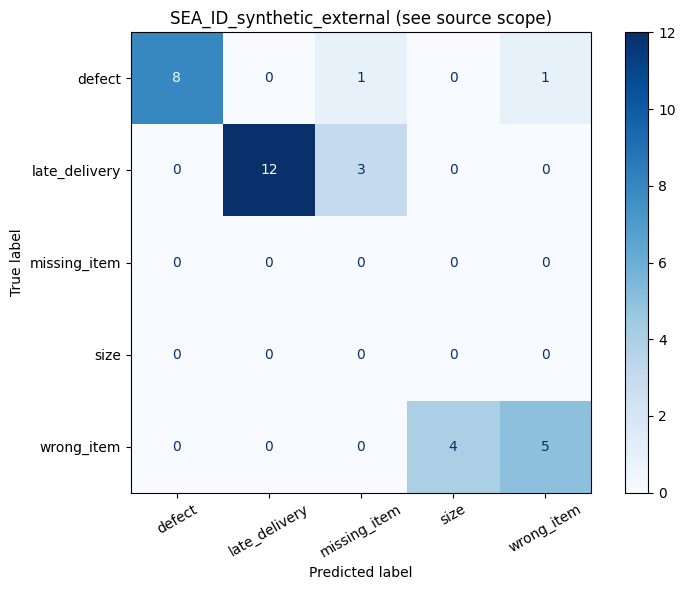

SEA_ID_synthetic_external N 34 accuracy 0.7353 macro F1 all 5 0.4889


In [9]:
def bert_predict(texts):
    import torch
    assert bert_model is not None and bert_tok is not None
    predictions=[]
    for i in range(0,len(texts),32):
        batch=bert_tok(list(map(str,texts[i:i+32])),padding=True,truncation=True,max_length=96,return_tensors='pt').to('cuda')
        with torch.no_grad(): ids=bert_model(**batch).logits.argmax(-1).cpu().tolist()
        predictions.extend(LABELS[j] for j in ids)
    return np.asarray(predictions)

use_bert=bool(bert_status.get('selected_for_release',False))
selected_name=MODEL_ID if use_bert else champion_name
predict_fn=bert_predict if use_bert else lambda texts: champion.predict(list(map(str,texts)))
print('SELECTED',selected_name,'(validation-only winner)')
def evaluate(df,name):
    if df.empty:
        return {'split':name,'rows':0,'status':'unavailable'}
    actual=df.label.astype(str).to_numpy()
    pred=predict_fn(df.text.astype(str).tolist())
    metrics={'split':name,'rows':int(len(df)),
             'accuracy':float(accuracy_score(actual,pred)),
             'macro_f1_all_five':float(f1_score(actual,pred,average='macro',labels=LABELS,zero_division=0)),
             'support':pd.Series(actual).value_counts().to_dict(),
             'classification_report':classification_report(actual,pred,labels=LABELS,output_dict=True,zero_division=0)}
    (OUT/'reports'/f'{name}_metrics.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8')
    errors=pd.DataFrame({'text':df.text.astype(str).to_numpy(),'actual':actual,'predicted':pred})
    # Do not export raw third-party texts into release package. Research reports remain in Kaggle working dir.
    errors.loc[errors.actual.ne(errors.predicted)].to_csv(OUT/'exports'/f'{name}_errors_RESEARCH_ONLY.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,6))
    ConfusionMatrixDisplay.from_predictions(actual,pred,labels=LABELS,xticks_rotation=30,ax=ax,cmap='Blues',values_format='d')
    ax.set_title(name+' (see source scope)');fig.tight_layout()
    fig.savefig(OUT/'assets/plots'/f'{name}_confusion_matrix.png',dpi=150);plt.show()
    print(name,'N',len(df),'accuracy',round(metrics['accuracy'],4),'macro F1 all 5',round(metrics['macro_f1_all_five'],4))
    return metrics
metrics_test=evaluate(test_id,'synthetic_family_heldout')
metrics_sea=evaluate(sea_id,'SEA_ID_synthetic_external')
metrics_gold=evaluate(gold,'human_verified_real_returns') if len(gold) else {'status':'not_available','rows':0}
print('WARNING: SEA lacks some classes; five-class Macro-F1 includes zero support for absent labels.')


## 9. Evidence-based smoke tests + reject/manual review policy

In [10]:
examples=[
 'Sepatu ini kekecilan, saya mau retur',
 'Ukuran kaosnya kebesaran dan tidak muat',
 'Lampunya rusak dan tidak bisa dinyalakan',
 'Saya pesan warna hitam tetapi dapat putih',
 'Paket sudah sampai tetapi charger tidak ada di dalamnya',
 'Barang tiba tiga hari melewati estimasi',
 'Paket belum diterima sampai sekarang, entah hilang atau terlambat',
 'Saya mau tanya ongkir saja',
]
expected=['size','size','defect','wrong_item','missing_item','late_delivery',None,None]
pr=predict_fn(examples)
demo=pd.DataFrame({'text':examples,'predicted_reason':pr,'expected_if_unambiguous':expected,'needs_human_review':True})
display(demo)
demo.to_csv(OUT/'exports/demo_predictions.csv',index=False)
print('Smoke correct among unambiguous cases:',sum(p==e for p,e in zip(pr,expected) if e is not None),'/',sum(e is not None for e in expected))
print('All predicted classes are suggestions; unknown or ambiguous input MUST allow Other/manual review.')


,text,predicted_reason,expected_if_unambiguous,needs_human_review
0,"Sepatu ini kekecilan, saya mau retur",size,size,True
1,Ukuran kaosnya kebesaran dan tidak muat,size,size,True
2,Lampunya rusak dan tidak bisa dinyalakan,defect,defect,True
3,Saya pesan warna hitam tetapi dapat putih,size,wrong_item,True
4,Paket sudah sampai tetapi charger tidak ada di...,missing_item,missing_item,True
5,Barang tiba tiga hari melewati estimasi,late_delivery,late_delivery,True
6,"Paket belum diterima sampai sekarang, entah hi...",missing_item,None,True
7,Saya mau tanya ongkir saja,missing_item,None,True


Smoke correct among unambiguous cases: 5 / 6
All predicted classes are suggestions; unknown or ambiguous input MUST allow Other/manual review.


## 10. Export inference artifacts (exact contract; no fake confidence)

In [11]:
if not use_bert:
    joblib.dump(champion,OUT/'models/returnreason_v3_tfidf.joblib',compress=3)
    back=joblib.load(OUT/'models/returnreason_v3_tfidf.joblib')
    assert np.array_equal(back.predict(examples),champion.predict(examples))
    model_file='returnreason_v3_tfidf.joblib';model_type='sklearn_tfidf_pipeline'
else:
    model_file='indobert/';model_type='huggingface_transformer'
config={'project':'ReturnReason Classifier','version':'full-master-v3','model_type':model_type,'model_file':model_file,
 'selected_model':selected_name,'classes':LABELS,'language':'Indonesian, experimental',
 'input_schema':{'text':'nonempty UTF-8 string'},
 'output_schema':{'predicted_reason':LABELS,'confidence_is_calibrated':False,'manual_review_required':True},
 'not_trained_on': ['Return Abuse categorical reason as self-labeled text','SEA external heldout','human verified evaluation'],
 'human_verified_test_rows':int(len(gold)),'human_verified_performance_validated':bool(len(gold)>0),
 'cautions':['Synthetic template training','No real-world performance claim without independently annotated gold','No other/reject learned class','SVM margins are NOT probabilities','SEA external only 34 samples/3 observed classes']}
(OUT/'models/model_config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
summary={'sources':source_manifest,'n_generated_synthetic':int(len(synthetic)),
 'n_synthetic_train':int(len(train_id)),'n_bitext_proxy_training':int(len(b_en)),
 'n_synthetic_validation':int(len(val_id)),'n_synthetic_test':int(len(test_id)),
 'n_sea_id_external':int(len(sea_id)),'n_human_verified_gold':int(len(gold)),
 'model_selected':selected_name,'model_type':model_type,
 'synthetic_family_heldout':{k:metrics_test[k] for k in ['rows','accuracy','macro_f1_all_five']},
 'sea_id_synthetic_external':{k:metrics_sea[k] for k in ['rows','accuracy','macro_f1_all_five']},
 'real_customer_metrics':('unavailable' if not len(gold) else {k:metrics_gold[k] for k in ['rows','accuracy','macro_f1_all_five']}),
 'claims':'Research prototype only; no proven real-customer classification quality.'}
(OUT/'reports/final_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
print('Model export:',model_type,model_file)


Model export: huggingface_transformer indobert/


## 11. Human annotation template for REAL improvement; include independent annotator agreement

In [12]:
annotation_template=pd.DataFrame([
 {'text':'','label':'','review_status':'unreviewed','annotator_id':'','source_permission':'','notes':''},
 {'text':'','label':'','review_status':'unreviewed','annotator_id':'','source_permission':'','notes':''}
])
annotation_template.to_csv(OUT/'exports/real_return_annotations_TEMPLATE.csv',index=False)
print('Prepare text,label,review_status=verified. Obtain consent/appropriate right to use; strip phone/address/order identifiers. Never label reviews as returns without evidence.')


Prepare text,label,review_status=verified. Obtain consent/appropriate right to use; strip phone/address/order identifiers. Never label reviews as returns without evidence.


## 12. Release archive — model, reports, plots, demo only; keep research text/private

In [13]:
README='# Day 19 ReturnReason FULL MASTER v3 — artifact contract\n\nThis is a research-only model. The 5 categories are defect, late_delivery, missing_item, size, wrong_item. Human approval/correction required for every operational case. Other and uncertain are reviewer actions; never force low-quality predictions.\n\n- models/model_config.json — exact inference metadata, claims and limits\n- models/returnreason_v3_tfidf.joblib or models/indobert/ — selected model\n- reports/ — training comparison, synthetic/SEA/gold evaluations, source audit\n- assets/plots/ — generated confusion matrices\n- exports/demo_predictions.csv — illustrative smoke outputs, NOT accuracy evidence\n- exports/real_return_annotations_TEMPLATE.csv — human annotations schema\n\nSources: Bitext https://huggingface.co/datasets/bitext/Bitext-retail-ecommerce-llm-chatbot-training-dataset ; Return Abuse https://huggingface.co/datasets/sarveshchhetri/E-commerce_return_abuse_detection_dataset ; SEA https://huggingface.co/datasets/nwchang/sea-ecommerce-customer-support-sample ; pretrained IndoBERT https://huggingface.co/indobenchmark/indobert-base-p1.\n\nOriginal third-party data, SEA raw message rows and generated training corpus are NOT redistributed in release. Model is only trained on synthetic Indonesian templates (and optionally English intent proxies). High synthetic test metrics are not evidence of production accuracy. Real gold is optional and is never used for model selection. Follow dataset license/privacy terms.\n'
(OUT/'README.md').write_text(README,encoding='utf-8')
release_files=[]
for name in ['models','reports','assets/plots']:
    release_files.extend(p for p in (OUT/name).rglob('*') if p.is_file())
release_files.extend([OUT/'README.md',OUT/'exports/demo_predictions.csv',OUT/'exports/real_return_annotations_TEMPLATE.csv'])
# Exclude private source filenames and any potentially sensitive gold reports beyond aggregate metrics
release_files=[p for p in release_files if p.name!='source_manifest.json']
checks={str(p.relative_to(OUT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in release_files}
(OUT/'reports/release_checksums.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
release_files.append(OUT/'reports/release_checksums.json')
archive=Path('/kaggle/working/ReturnReason_Day19_FULL_MASTER_v3_RELEASE.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in release_files:z.write(p,p.relative_to(OUT))
print('ARCHIVE:',archive,'MB',round(archive.stat().st_size/2**20,2))
print('\n'.join(map(str,(p.relative_to(OUT) for p in release_files))))


ARCHIVE: /kaggle/working/ReturnReason_Day19_FULL_MASTER_v3_RELEASE.zip MB 440.99
models/model_config.json
models/indobert/model.safetensors
models/indobert/tokenizer.json
models/indobert/tokenizer_config.json
models/indobert/config.json
reports/synthetic_family_heldout_metrics.json
reports/synthetic_generation_contract.json
reports/indobert_training_history.csv
reports/SEA_ID_synthetic_external_metrics.json
reports/model_comparison.csv
reports/indobert_status.json
reports/split_class_counts.csv
reports/final_summary.json
assets/plots/synthetic_family_heldout_confusion_matrix.png
assets/plots/SEA_ID_synthetic_external_confusion_matrix.png
README.md
exports/demo_predictions.csv
exports/real_return_annotations_TEMPLATE.csv
reports/release_checksums.json


## Final scientific decision gate

- **If 0 human gold examples:** you may demo the app as a **synthetic-data prototype**, not as a reliable Indonesian return classifier.
- **If size smoke remains wrong:** export failures and annotate true varied user language instead of repeating near-identical templates. Do not hand-write a hardcoded fix and call it machine learning improvement.
- **If external SEA remains poor:** model is domain sensitive; source-specific validation is essential.
- **To support production claim:** obtain consented return reasons with human-verified labels, add an `other` cohort, multiple annotators and adjudication, strict unseen heldout/test, manual override. Re-run experiments with untouched evaluation.

The notebook intentionally does **not** automatically scrape marketplace messages or convert Indonesian product reviews into "return reasons" (that would create fabricated labels).